In [2]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Rutas 
PROYECTO = Path("..")
BASE = PROYECTO / "base_expresiones_faciales"
DATASET = BASE / "DATASET"
RESULTADOS = PROYECTO / "Resultados"
GRAFICOS = PROYECTO / "Graficos"

# Número de carpeta a emoción
EMOCIONES = {
    1: "Sorpresa",
    2: "Miedo",
    3: "Asco",
    4: "Felicidad",
    5: "Tristeza",
    6: "Enojo",
    7: "Neutral",
}

# Control: si alguna ruta no existe, el error avisa cuál
for ruta in [DATASET / "train", DATASET / "test", BASE / "train_labels.csv", BASE / "test_labels.csv"]:
    assert ruta.exists(), f"No se encontró: {ruta.resolve()}"
print("Rutas correctas")

Rutas correctas


In [3]:
filas = []
for split in ["train", "test"]:
    for carpeta in sorted((DATASET / split).iterdir()):
        if not carpeta.is_dir():
            continue
        for archivo in carpeta.iterdir():
            if archivo.is_file():
                filas.append({
                    "split": split,
                    "carpeta": int(carpeta.name),
                    "archivo": archivo.name,
                    "extension": archivo.suffix.lower(),
                    "ruta": str(archivo),
                })

df_carpetas = pd.DataFrame(filas)
print(f"Archivos encontrados: {len(df_carpetas)}")
print()
print("Archivos por split:")
print(df_carpetas["split"].value_counts())
print()
print("Extensiones encontradas:")
print(df_carpetas["extension"].value_counts())

Archivos encontrados: 15339

Archivos por split:
split
train    12271
test      3068
Name: count, dtype: int64

Extensiones encontradas:
extension
.jpg    15339
Name: count, dtype: int64


In [4]:
# Lee los CSV, los une y cambia el nombre de las columnas para leerlos mejor
csv_train = pd.read_csv(BASE / "train_labels.csv").assign(split="train")
csv_test = pd.read_csv(BASE / "test_labels.csv").assign(split="test")
df_csv = pd.concat([csv_train, csv_test], ignore_index=True)
df_csv = df_csv.rename(columns={"image": "archivo", "label": "etiqueta_csv"})

print(f"Filas en train_labels.csv: {len(csv_train)}")
print(f"Filas en test_labels.csv:  {len(csv_test)}")
print()
print(f"Nombres repetidos en los CSV: {df_csv.duplicated(['split', 'archivo']).sum()}")
print()
print("Valores de etiqueta encontrados:", sorted(df_csv["etiqueta_csv"].unique().tolist()))
df_csv.head()

Filas en train_labels.csv: 12271
Filas en test_labels.csv:  3068

Nombres repetidos en los CSV: 0

Valores de etiqueta encontrados: [1, 2, 3, 4, 5, 6, 7]


,archivo,etiqueta_csv,split
0,train_00001_aligned.jpg,5,train
1,train_00002_aligned.jpg,5,train
2,train_00003_aligned.jpg,4,train
3,train_00004_aligned.jpg,4,train
4,train_00005_aligned.jpg,5,train


In [5]:
# control de diferencia entre la carpeta y el CSV

df = df_carpetas.merge(df_csv, on=["split", "archivo"], how="outer", indicator=True)

def estado(fila):
    if fila["_merge"] == "left_only":
        return "Solo en carpeta"
    if fila["_merge"] == "right_only":
        return "Solo en CSV"
    if fila["carpeta"] == fila["etiqueta_csv"]:
        return "Coincide"
    return "Etiqueta distinta"

df["verificacion"] = df.apply(estado, axis=1)
df = df.drop(columns="_merge")

print(pd.crosstab(df["verificacion"], df["split"], margins=True, margins_name="Total"))
print()
problemas = df[df["verificacion"] != "Coincide"]
print(f"Casos con diferencias: {len(problemas)}")
problemas.head(20)


split         test  train  Total
verificacion                    
Coincide      3068  12271  15339
Total         3068  12271  15339

Casos con diferencias: 0


,split,carpeta,archivo,extension,ruta,etiqueta_csv,verificacion


In [6]:
# Revisa tamaño de iamgenes y si estan dañadas
legible, ancho, alto, modo = [], [], [], []

rutas = df["ruta"].fillna("")
for ruta in rutas:
    if not ruta:  # imágenes que figuran solo en el CSV
        legible.append(None); ancho.append(None); alto.append(None); modo.append(None)
        continue
    try:
        with Image.open(ruta) as im:
            im.verify()  # detecta archivos dañados
        with Image.open(ruta) as im:
            legible.append(True); ancho.append(im.width); alto.append(im.height); modo.append(im.mode)
    except Exception:
        legible.append(False); ancho.append(None); alto.append(None); modo.append(None)

df["legible"] = legible
df["ancho"] = pd.array(ancho, dtype="Int64")
df["alto"] = pd.array(alto, dtype="Int64")
df["modo_color"] = modo

print(f"Imágenes que no se pudieron abrir: {df['legible'].eq(False).sum()}")
print()
print("Tamaños encontrados (ancho x alto):")
print(df[df["legible"].eq(True)].groupby(["ancho", "alto"]).size().sort_values(ascending=False))
print()
print("Modos de color encontrados:")
print(df["modo_color"].value_counts(dropna=False))

Imágenes que no se pudieron abrir: 0

Tamaños encontrados (ancho x alto):
ancho  alto
100    100     15339
dtype: int64

Modos de color encontrados:
modo_color
RGB    15339
Name: count, dtype: int64


In [7]:
# cuenta las imagenes por emocion y calcula el porcentaje de cada una
df["emocion"] = df["carpeta"].map(EMOCIONES)

conteo = pd.crosstab(df["emocion"], df["split"], margins=True, margins_name="Total")
conteo = conteo[["train", "test", "Total"]]
conteo["% del total"] = (conteo["Total"] / len(df[df["carpeta"].notna()]) * 100).round(1)

# Ordenar de mayor a menor
conteo = pd.concat([conteo.drop(index="Total").sort_values("Total", ascending=False),
                    conteo.loc[["Total"]]])

por_emocion = conteo.drop(index="Total")["Total"]
mayor, menor = por_emocion.idxmax(), por_emocion.idxmin()
print(f"Emoción con más imágenes:   {mayor} ({por_emocion.max()})")
print(f"Emoción con menos imágenes: {menor} ({por_emocion.min()})")
print(f"Relación entre ambas: {por_emocion.max() / por_emocion.min():.1f} veces")

conteo

Emoción con más imágenes:   Felicidad (5957)
Emoción con menos imágenes: Miedo (355)
Relación entre ambas: 16.8 veces


split,train,test,Total,% del total
emocion,,,,
Felicidad,4772,1185,5957,38.8
Neutral,2524,680,3204,20.9
Tristeza,1982,478,2460,16.0
Sorpresa,1290,329,1619,10.6
Asco,717,160,877,5.7
Enojo,705,162,867,5.7
Miedo,281,74,355,2.3
Total,12271,3068,15339,100.0


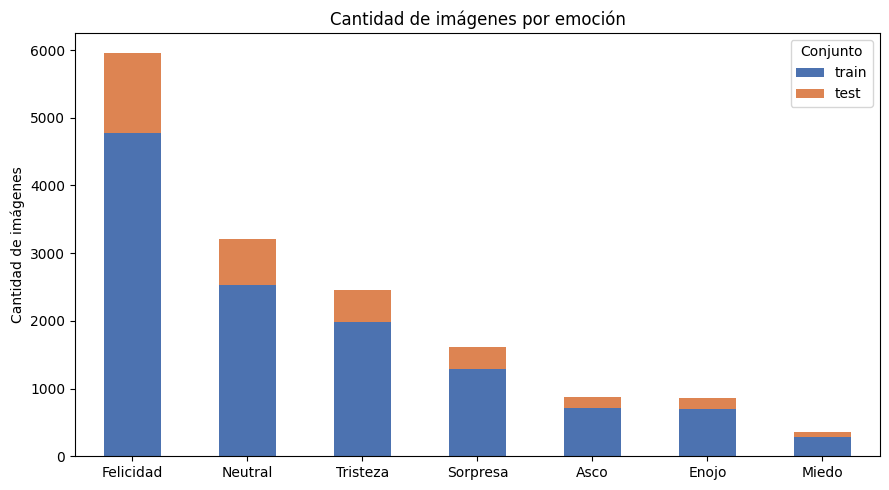

In [8]:
#grafico de emociones por cantidad
tabla = conteo.drop(index="Total")[["train", "test"]]

ax = tabla.plot(kind="bar", stacked=True, figsize=(9, 5), color=["#4C72B0", "#DD8452"])
ax.set_title("Cantidad de imágenes por emoción")
ax.set_xlabel("")
ax.set_ylabel("Cantidad de imágenes")
ax.legend(title="Conjunto")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(GRAFICOS / "01_imagenes_por_emocion.png", dpi=150)
plt.show()

In [9]:
#acomoda las columnas para PowerBI
columnas = ["split", "carpeta", "emocion", "archivo", "etiqueta_csv", "verificacion",
            "legible", "ancho", "alto", "modo_color", "ruta"]
df[columnas].to_csv(RESULTADOS / "inventario.csv", index=False, encoding="utf-8-sig")
print(f"Guardado: {(RESULTADOS / 'inventario.csv').resolve()}")

Guardado: C:\Proyecto\Resultados\inventario.csv
